# Лабораторная работа № 3

## Модель камеры, проективная геометрия и стереопара

**Дисциплина:** Введение в технологии виртуальной дополненной реальности и робототехники
**Тема курса:** 4. Проективная геометрия и модель камеры. Стереоскопия и рендеринг в VR

---

**Студент:** _фамилия, имя, группа_
**Дата:**

---

### Цель работы

Реализовать полный конвейер «модель — мир — камера — изображение», смоделировать
стереопару и убедиться численно, что погрешность восстановления глубины растёт
пропорционально квадрату расстояния и обратно пропорционально базе.

### Что понадобится

`numpy`, `matplotlib`. Графические библиотеки не нужны: рендеринг вы напишете сами.
`opencv-python` — только для сверки в заданиях 3 и 7.

### Правило практикума

Алгоритм вы реализуете сами. `cv2.projectPoints`, `cv2.undistortPoints`,
`cv2.triangulatePoints` допустимо использовать **только** для сверки — и такую сверку
нужно показать явно.

## Теоретическая справка

### Модель камеры-обскуры

Точка $X$ в системе координат камеры проецируется на плоскость изображения делением
на глубину. В однородных координатах это записывается линейно:

$$
\tilde{x} \;=\; K\,[\,R \mid t\,]\,\tilde{X},
\qquad
K = \begin{pmatrix} f & 0 & c_x \\ 0 & f & c_y \\ 0 & 0 & 1\end{pmatrix}.
$$

Матрица $K$ содержит **внутренние** параметры (фокусное расстояние в пикселях
и главную точку), пара $[R \mid t]$ — **внешние**, то есть положение камеры в мире.
Именно здесь пригождается аппарат тем 2 и 3: $[R \mid t]$ — это в точности элемент
$SE(3)$, только записанный блоком $3\times4$.

Заметьте, что нижняя строка полной матрицы $4\times4$ здесь перестала быть $(0,0,0,1)$:
преобразование стало **проективным**, а не аффинным. Отсюда деление на третью
координату — то самое, из-за которого далёкие предметы кажутся меньше.

### Дисторсия

Реальный объектив искажает изображение. Стандартная модель Брауна — Конради
в нормированных координатах ($x_n = (u - c_x)/f$):

$$
\begin{aligned}
x_d &= x\,(1 + k_1 r^2 + k_2 r^4) + 2p_1 x y + p_2 (r^2 + 2x^2),\\
y_d &= y\,(1 + k_1 r^2 + k_2 r^4) + p_1 (r^2 + 2y^2) + 2p_2 x y,
\end{aligned}
\qquad r^2 = x^2 + y^2 .
$$

Первые слагаемые — радиальная дисторсия (бочка при $k_1 < 0$, подушка при $k_1 > 0$),
вторые — тангенциальная, от перекоса матрицы относительно оптической оси.
Обратного преобразования в замкнутой форме нет: его находят итерациями.

Ровно эта же модель применяется в VR-шлеме, только в обратную сторону: изображение
заранее искажают, чтобы линза выпрямила его обратно.

### Стереопара

Две камеры с одинаковой ориентацией, разнесённые на базу $B$ вдоль оси $x$.
Точка с глубиной $z$ проецируется в них со сдвигом — **диспаратностью**:

$$d = u_L - u_R = \frac{fB}{z}, \qquad\text{откуда}\qquad z = \frac{fB}{d}.$$

Дифференцируя, получаем закон роста погрешности:

$$\delta z = \frac{z^2}{fB}\,\delta d .$$

Это соотношение вы проверите численно. Из него следуют все инженерные решения:
почему стереозрение не работает вдаль, почему у марсоходов камеры разнесены
на десятки сантиметров и почему в VR-шлеме межзрачковое расстояние — параметр модели,
а не настройка удобства.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

## Задание 1. Модель камеры и матрица проекции

Реализуйте `intrinsics(f, cx, cy)`, `look_at(eye, target, up)` и `project(K, R, t, X)`.

`look_at` должна возвращать пару $(R, t)$ такую, что $X_{cam} = R X_{world} + t$,
причём оптическая ось камеры — это $+z$.

`project` должна принимать массив точек $N\times3$ и возвращать пиксельные координаты
$N\times2$ вместе с глубиной.

**Контроль.** Точка, лежащая на оптической оси, обязана спроецироваться точно
в главную точку $(c_x, c_y)$. Проверьте также, что $\det R = 1$ и $R^{\mathsf T}R = I$
с точностью до машинной погрешности.

In [2]:
import numpy as np

def intrinsics(f, cx, cy):
    """
    Формирует матрицу внутренних параметров камеры K (3x3).
    """
    return np.array([
        [f,  0.0, cx],
        [0.0, f,  cy],
        [0.0, 0.0, 1.0]
    ], dtype=float)


def look_at(eye, target, up):
    """
    Вычисляет внешние параметры камеры (R, t) такие, что X_cam = R @ X_world + t.
    Оптическая ось камеры направлена вдоль +z, ось +y — вниз (согласовано с экраном),
    ось +x — вправо. Тройка векторов правая: det(R) = 1, R^T @ R = I.
    """
    eye = np.asarray(eye, dtype=float)
    target = np.asarray(target, dtype=float)
    up = np.asarray(up, dtype=float)

    # Оптическая ось (+z) направлена от центра камеры к цели
    z_axis = target - eye
    z_axis = z_axis / np.linalg.norm(z_axis)

    # Ось +x направлена вправо: векторное произведение (z x up) при оси y "вниз"
    x_axis = np.cross(z_axis, up)
    x_axis = x_axis / np.linalg.norm(x_axis)

    # Ось +y направлена вниз, завершая правую ортонормированную систему координат
    y_axis = np.cross(z_axis, x_axis)

    # Матрица вращения R переводит координаты из базиса мира в базис камеры
    R = np.vstack([x_axis, y_axis, z_axis])
    
    # Вектор сдвига t в системе координат камеры
    t = -R @ eye

    return R, t


def project(K, R, t, X):
    """
    Проецирует массив 3D-точек X (N x 3) на плоскость изображения.
    Возвращает:
      uv: пиксельные координаты (N x 2)
      depths: глубины точек вдоль оптической оси камеры z_cam (N,)
    """
    X = np.atleast_2d(X).astype(float)

    # 1. Переход в систему координат камеры: X_cam = R @ X_world + t
    X_cam = (R @ X.T).T + t
    depths = X_cam[:, 2]

    # 2. Проективное преобразование и переход к однородным координатам на плоскости
    x_hom = (K @ X_cam.T).T

    # 3. Нормализация (деление на глубину z_cam)
    uv = x_hom[:, :2] / x_hom[:, 2:3]

    return uv, depths


# ==================== БЛОК КОНТРОЛЯ ====================
if __name__ == "__main__":
    f, cx, cy = 800.0, 640.0, 360.0
    K = intrinsics(f, cx, cy)

    eye = np.array([3.0, -4.0, 2.0])
    target = np.array([0.0, 0.0, 0.5])
    up = np.array([0.0, 0.0, 1.0])

    R, t = look_at(eye, target, up)

    # 1. Проверка свойств матрицы R (det R = 1 и ортогональность R^T R = I)
    det_R = np.linalg.det(R)
    ortho_error = np.linalg.norm(R.T @ R - np.eye(3))

    print(f"det(R) = {det_R:.16f} (отклонение: {abs(det_R - 1.0):.2e})")
    print(f"||R^T R - I|| = {ortho_error:.2e}")

    assert np.isclose(det_R, 1.0, atol=1e-14), "Ошибка: определитель R должен быть равен 1!"
    assert np.allclose(R.T @ R, np.eye(3), atol=1e-14), "Ошибка: матрица R не ортогональна!"

    # 2. Проверка проекции точек, лежащих на оптической оси камеры
    # Луч оптической оси: eye + alpha * (target - eye), где alpha > 0
    X_optical_axis = np.array([
        eye + 0.5 * (target - eye),
        target,
        eye + 2.0 * (target - eye)
    ])

    uv_proj, depths_proj = project(K, R, t, X_optical_axis)

    print(f"\nПроекция точек на оптической оси (ожидается главная точка [{cx}, {cy}]):")
    for i, (pt, z) in enumerate(zip(uv_proj, depths_proj)):
        print(f"  Точка {i+1}: u = {pt[0]:.4f}, v = {pt[1]:.4f}, глубина z = {z:.4f}")

    assert np.allclose(uv_proj, [cx, cy], atol=1e-12), "Ошибка: проекция не совпала с главной точкой!"
    print("\nВсе контрольные проверки успешно пройдены!")


det(R) = 0.9999999999999998 (отклонение: 2.22e-16)
||R^T R - I|| = 2.27e-16

Проекция точек на оптической оси (ожидается главная точка [640.0, 360.0]):
  Точка 1: u = 640.0000, v = 360.0000, глубина z = 2.6101
  Точка 2: u = 640.0000, v = 360.0000, глубина z = 5.2202
  Точка 3: u = 640.0000, v = 360.0000, глубина z = 10.4403

Все контрольные проверки успешно пройдены!


## Задание 2. Каркасный рендеринг без графических библиотек

Задайте восемь вершин параллелепипеда и постройте список его рёбер программно
(два узла соединены ребром, если их координаты различаются ровно по одной оси).

Спроецируйте вершины и нарисуйте рёбра средствами Matplotlib. Отметьте главную точку.
Не забудьте, что ось $v$ изображения направлена вниз.

**Контроль.** Рёбер должно получиться ровно 12, все вершины — перед камерой ($z > 0$).

**Вопрос для вывода:** что произойдёт с картинкой, если точка окажется позади камеры,
и почему проверку $z > 0$ приходится делать явно?

Количество вершин: 8
Количество найденных рёбер: 12 (ожидается: 12)
Минимальная глубина z: 4.0420 м (все z > 0: True)


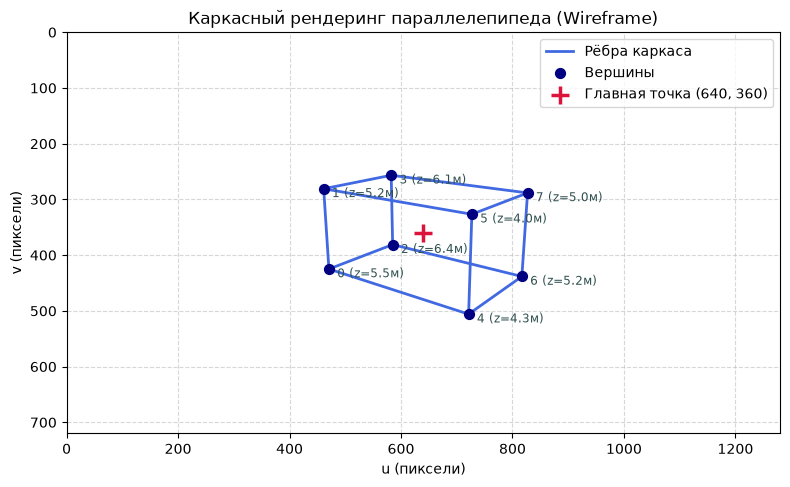

In [3]:
# ==================== 1. ЗАДАНИЕ ВЕРШИН ПАРАЛЛЕЛЕПИПЕДА ====================
# Выбираем размеры объекта (например, 2 x 1.2 x 1 м) и располагаем его перед камерой
x_vals = [-1.0, 1.0]
y_vals = [-0.6, 0.6]
z_vals = [0.0, 1.0]

# Формируем 8 вершин через декартово произведение
vertices = np.array([[x, y, z] for x in x_vals for y in y_vals for z in z_vals], dtype=float)

# ==================== 2. ПРОГРАММНЫЙ ПОИСК РЁБЕР ====================
# Две вершины соединены ребром, если они различаются ровно по одной координатной оси
edges = []
n_verts = len(vertices)
for i in range(n_verts):
    for j in range(i + 1, n_verts):
        diff_axes = np.sum(~np.isclose(vertices[i], vertices[j]))
        if diff_axes == 1:
            edges.append((i, j))

# ==================== 3. ПРОЕКЦИЯ ВЕРШИН ====================
# Используем параметры камеры и функции intrinsics, look_at, project из Задания 1
f, cx, cy = 800.0, 640.0, 360.0
K = intrinsics(f, cx, cy)

eye = np.array([3.0, -4.0, 2.0])
target = np.array([0.0, 0.0, 0.5])
up = np.array([0.0, 0.0, 1.0])

R, t = look_at(eye, target, up)

uv_verts, depths = project(K, R, t, vertices)

# ==================== КОНТРОЛЬ ====================
print(f"Количество вершин: {len(vertices)}")
print(f"Количество найденных рёбер: {len(edges)} (ожидается: 12)")
print(f"Минимальная глубина z: {depths.min():.4f} м (все z > 0: {np.all(depths > 0)})")

assert len(edges) == 12, f"Ошибка: ожидалось 12 рёбер, получено {len(edges)}!"
assert np.all(depths > 0), "Ошибка: есть вершины позади плоскости камеры (z <= 0)!"

# ==================== 4. ОТРИСОВКА СРЕДСТВАМИ MATPLOTLIB ====================
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

# Отрисовка 12 каркасных рёбер
for idx, (i, j) in enumerate(edges):
    ax.plot(
        [uv_verts[i, 0], uv_verts[j, 0]],
        [uv_verts[i, 1], uv_verts[j, 1]],
        color="royalblue",
        linewidth=2,
        label="Рёбра каркаса" if idx == 0 else None
    )

# Отрисовка вершин с подписями индексов и глубин
ax.scatter(uv_verts[:, 0], uv_verts[:, 1], color="navy", s=50, zorder=4, label="Вершины")
for idx, (u, v) in enumerate(uv_verts):
    ax.annotate(
        f"{idx} (z={depths[idx]:.1f}м)",
        (u, v),
        textcoords="offset points",
        xytext=(6, -6),
        fontsize=8.5,
        color="darkslategray"
    )

# Главная точка (cx, cy)
ax.scatter([cx], [cy], color="crimson", marker="+", s=150, linewidths=2.5, zorder=5, label=f"Главная точка ({cx:.0f}, {cy:.0f})")

# Настройка осей и экранных координат (ось v направлена вниз)
ax.set_xlim(0, 2 * cx)
ax.set_ylim(2 * cy, 0)  # Обратный порядок инвертирует ось v вниз
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.5)

ax.set_xlabel("u (пиксели)")
ax.set_ylabel("v (пиксели)")
ax.set_title("Каркасный рендеринг параллелепипеда (Wireframe)")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

## Задание 3. Дисторсия и её компенсация

Реализуйте `distort(xn, k1, k2, p1, p2)` по модели из справки и `undistort(...)` —
итерационным методом простой итерации.

Постройте правильную сетку в нормированных координатах, примените дисторсию
и нарисуйте обе сетки рядом. Возьмите $k_1 = -0{,}28$, $k_2 = 0{,}09$.

**Контроль.** $\|\,\mathrm{undistort}(\mathrm{distort}(x)) - x\,\| < 10^{-12}$.

**Вопросы для вывода:** какой тип искажения даёт отрицательный $k_1$? Почему обратное
преобразование приходится искать итерациями? Сколько итераций нужно для машинной
точности — проверьте.

Погрешность ||undistort(distort(x)) - x|| (25 итераций): 2.831e-16
Точность < 1e-12 достигается на 17-й итерации (ошибка: 7.353e-13)
Машинная точность (< 1e-15) достигается на 22-й итерации (ошибка: 4.228e-16)

Модуль opencv-python не найден или функция сверки недоступна, сверка пропущена.


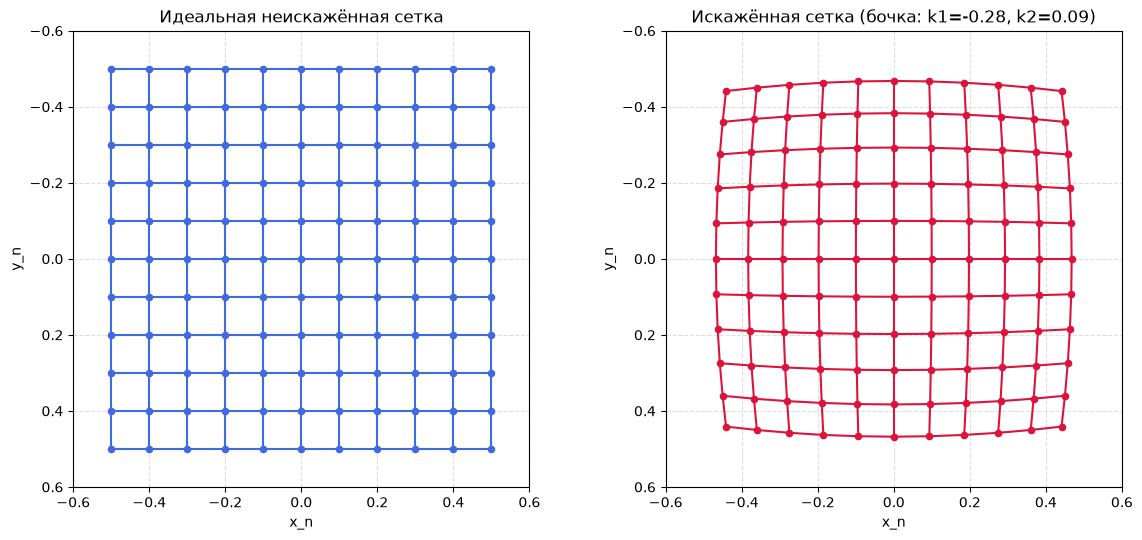

In [4]:
# ==================== 1. ФУНКЦИИ ДИСТОРСИИ И ЕЁ КОМПЕНСАЦИИ ====================
def distort(xn, k1=-0.28, k2=0.09, p1=0.0, p2=0.0):
    """
    Прямая модель дисторсии Брауна — Конради в нормированных координатах.
    Принимает:
      xn: массив координат (N, 2)
    Возвращает:
      xd: искажённые координаты (N, 2)
    """
    xn = np.atleast_2d(xn).astype(float)
    x = xn[:, 0]
    y = xn[:, 1]
    
    r2 = x**2 + y**2
    r4 = r2**2
    radial = 1.0 + k1 * r2 + k2 * r4
    
    dx_tang = 2.0 * p1 * x * y + p2 * (r2 + 2.0 * x**2)
    dy_tang = p1 * (r2 + 2.0 * y**2) + 2.0 * p2 * x * y
    
    xd = x * radial + dx_tang
    yd = y * radial + dy_tang
    
    return np.column_stack([xd, yd])


def undistort(xd_arr, k1=-0.28, k2=0.09, p1=0.0, p2=0.0, num_iters=25):
    """
    Компенсация дисторсии методом простой итерации (fixed-point iteration).
    Принимает:
      xd_arr: искажённые нормированные координаты (N, 2)
    Возвращает:
      xn_recovered: восстановленные координаты (N, 2)
    """
    xd_arr = np.atleast_2d(xd_arr).astype(float)
    xd = xd_arr[:, 0]
    yd = xd_arr[:, 1]
    
    # Начальное приближение: x^(0) = x_d
    x = xd.copy()
    y = yd.copy()
    
    for _ in range(num_iters):
        r2 = x**2 + y**2
        r4 = r2**2
        radial = 1.0 + k1 * r2 + k2 * r4
        
        dx_tang = 2.0 * p1 * x * y + p2 * (r2 + 2.0 * x**2)
        dy_tang = p1 * (r2 + 2.0 * y**2) + 2.0 * p2 * x * y
        
        x = (xd - dx_tang) / radial
        y = (yd - dy_tang) / radial
        
    return np.column_stack([x, y])


# ==================== 2. СЕТКА И ВЫЧИСЛЕНИЯ ====================
k1, k2 = -0.28, 0.09
p1, p2 = 0.0, 0.0

# Правильная сетка 11x11 в диапазоне [-0.5, 0.5] x [-0.5, 0.5]
grid_1d = np.linspace(-0.5, 0.5, 11)
gx, gy = np.meshgrid(grid_1d, grid_1d)
xn_grid = np.column_stack([gx.ravel(), gy.ravel()])

# Применяем дисторсию и обратное восстановление
xd_grid = distort(xn_grid, k1=k1, k2=k2, p1=p1, p2=p2)
xn_rec = undistort(xd_grid, k1=k1, k2=k2, p1=p1, p2=p2, num_iters=25)


# ==================== 3. КОНТРОЛЬ И СХОДИМОСТЬ ====================
err_25 = np.linalg.norm(xn_rec - xn_grid)
print(f"Погрешность ||undistort(distort(x)) - x|| (25 итераций): {err_25:.3e}")
assert err_25 < 1e-12, "Ошибка: не достигнута требуемая точность 1e-12!"

# Оценка необходимого числа итераций
iter_12 = None
iter_eps = None

for it in range(1, 40):
    rec_it = undistort(xd_grid, k1=k1, k2=k2, p1=p1, p2=p2, num_iters=it)
    err_it = np.linalg.norm(rec_it - xn_grid)
    if iter_12 is None and err_it < 1e-12:
        iter_12 = (it, err_it)
    if iter_eps is None and err_it < 1e-15:
        iter_eps = (it, err_it)
        break

print(f"Точность < 1e-12 достигается на {iter_12[0]}-й итерации (ошибка: {iter_12[1]:.3e})")
if iter_eps:
    print(f"Машинная точность (< 1e-15) достигается на {iter_eps[0]}-й итерации (ошибка: {iter_eps[1]:.3e})")

# ==================== 4. СВЕРКА С OPENCV ====================
try:
    import cv2
    dist_coeffs = np.array([k1, k2, p1, p2, 0.0], dtype=float)
    
    # 1. Сверка прямого преобразования через cv2.projectPoints
    pts_3d = np.column_stack([xn_grid, np.ones(len(xn_grid))])
    cv_xd, _ = cv2.projectPoints(pts_3d, np.zeros(3), np.zeros(3), np.eye(3), dist_coeffs)
    cv_xd = cv_xd.reshape(-1, 2)
    err_cv_forward = np.linalg.norm(xd_grid - cv_xd)
    
    # 2. Сверка обратного преобразования через cv2.undistortPointsIter
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-15)
    cv_xn = cv2.undistortPointsIter(
        xd_grid.reshape(-1, 1, 2), np.eye(3), dist_coeffs, None, None, criteria
    ).reshape(-1, 2)
    err_cv_inv = np.linalg.norm(xn_rec - cv_xn)
    
    print("\nСверка с OpenCV:")
    print(f"  ||distort - cv2.projectPoints||        = {err_cv_forward:.3e}")
    print(f"  ||undistort - cv2.undistortPointsIter|| = {err_cv_inv:.3e}")
except (ImportError, AttributeError):
    print("\nМодуль opencv-python не найден или функция сверки недоступна, сверка пропущена.")


# ==================== 5. ОТРИСОВКА СЕТОК РЯДОМ ====================
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), dpi=100)
n_side = len(grid_1d)

G_orig = xn_grid.reshape(n_side, n_side, 2)
G_dist = xd_grid.reshape(n_side, n_side, 2)

configs = [
    (axes[0], G_orig, "Идеальная неискажённая сетка", "royalblue"),
    (axes[1], G_dist, f"Искажённая сетка (бочка: k1={k1}, k2={k2})", "crimson")
]

for ax, G, title, color in configs:
    for i in range(n_side):
        ax.plot(G[i, :, 0], G[i, :, 1], color=color, lw=1.5)
        ax.plot(G[:, i, 0], G[:, i, 1], color=color, lw=1.5)
    ax.scatter(G[:, :, 0], G[:, :, 1], color=color, s=20, zorder=3)
    ax.set_title(title)
    ax.set_xlabel("x_n")
    ax.set_ylabel("y_n")
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(0.6, -0.6)  # Ось y направлена вниз (согласовано с экраном)
    ax.set_aspect("equal")
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## Задание 4. Стереопара и восстановление глубины

Реализуйте `stereo_project(P, f, B, cx)`: две камеры с одинаковой ориентацией,
правая смещена на $+B$ вдоль оси $x$.

Для набора глубин $0{,}5\ldots16$ м вычислите диспаратность и восстановите глубину
по формуле $z = fB/d$. Сведите в таблицу истинную глубину, диспаратность
и восстановленную глубину.

**Контроль.** Без шума расхождение должно быть на уровне машинной погрешности.

**Вопрос для вывода:** как меняется диспаратность при удвоении глубины? Какой
диспаратности отвечает бесконечно удалённая точка?

In [5]:
# ==================== 1. ФУНКЦИЯ ПРОЕКЦИИ СТЕРЕОПАРЫ ====================
def stereo_project(P, f, B, cx, cy=360.0):
    """
    Проецирует массив 3D-точек P (N x 3) на стереопару с одинаковой ориентацией.
    Левая камера находится в начале координат мира, правая смещена на +B по оси x.
    Возвращает:
      u_L: горизонтальные координаты на левом кадре (N,)
      u_R: горизонтальные координаты на правом кадре (N,)
      d: диспаратность d = u_L - u_R (N,)
    """
    P = np.atleast_2d(P).astype(float)
    K = intrinsics(f, cx, cy)
    R_id = np.eye(3)
    
    # Векторы переноса (X_cam = R @ X_world + t):
    # Левая камера в eye_L = [0, 0, 0] -> t_L = [0, 0, 0]
    # Правая камера в eye_R = [B, 0, 0] -> t_R = -R @ eye_R = [-B, 0, 0]
    t_L = np.array([0.0, 0.0, 0.0])
    t_R = np.array([-B, 0.0, 0.0])
    
    uv_L, _ = project(K, R_id, t_L, P)
    uv_R, _ = project(K, R_id, t_R, P)
    
    u_L = uv_L[:, 0]
    u_R = uv_R[:, 0]
    disparity = u_L - u_R
    
    return u_L, u_R, disparity


# ==================== 2. РАСЧЁТ И ВОССТАНОВЛЕНИЕ ГЛУБИНЫ ====================
f_val = 800.0   # Фокусное расстояние в пикселях
B_val = 0.12    # База стереопары в метрах (12 см)
cx_val = 640.0  # Главная точка u0

# Набор глубин от 0.5 до 16 м
z_true = np.array([0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0, 16.0])

# Точки перед стереопарой (например, с небольшим поперечным смещением x=0.2, y=-0.1)
P_points = np.column_stack([
    0.2 * np.ones_like(z_true),
    -0.1 * np.ones_like(z_true),
    z_true
])

# Проецирование и восстановление глубины
u_L, u_R, d = stereo_project(P_points, f_val, B_val, cx_val)
z_rec = (f_val * B_val) / d
errors = np.abs(z_rec - z_true)


# ==================== 3. СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ ====================
header = f"{'z_ист (м)':>10} | {'u_L (пикс)':>12} | {'u_R (пикс)':>12} | {'d (пикс)':>10} | {'z_восст (м)':>12} | {'|ошибка| (м)':>13}"
print(header)
print("-" * len(header))

for z_t, ul, ur, d_val, z_r, err in zip(z_true, u_L, u_R, d, z_rec, errors):
    print(f"{z_t:10.2f} | {ul:12.4f} | {ur:12.4f} | {d_val:10.4f} | {z_r:12.6f} | {err:13.3e}")


# ==================== 4. БЛОК КОНТРОЛЯ ====================
max_err = np.max(errors)
print(f"\nМаксимальное расхождение: {max_err:.3e} м")
assert np.allclose(z_rec, z_true, atol=1e-12), "Ошибка: расхождение превышает машинную точность!"
print("Контрольная проверка пройдена: аналитическая формула согласуется с проекцией с машинной точностью.")


 z_ист (м) |   u_L (пикс) |   u_R (пикс) |   d (пикс) |  z_восст (м) |  |ошибка| (м)
------------------------------------------------------------------------------------
      0.50 |     960.0000 |     768.0000 |   192.0000 |     0.500000 |     0.000e+00
      1.00 |     800.0000 |     704.0000 |    96.0000 |     1.000000 |     0.000e+00
      1.50 |     746.6667 |     682.6667 |    64.0000 |     1.500000 |     0.000e+00
      2.00 |     720.0000 |     672.0000 |    48.0000 |     2.000000 |     0.000e+00
      3.00 |     693.3333 |     661.3333 |    32.0000 |     3.000000 |     0.000e+00
      4.00 |     680.0000 |     656.0000 |    24.0000 |     4.000000 |     0.000e+00
      6.00 |     666.6667 |     650.6667 |    16.0000 |     6.000000 |     0.000e+00
      8.00 |     660.0000 |     648.0000 |    12.0000 |     8.000000 |     0.000e+00
     12.00 |     653.3333 |     645.3333 |     8.0000 |    12.000000 |     0.000e+00
     16.00 |     650.0000 |     644.0000 |     6.0000 |    16.000

## Задание 5. Погрешность глубины растёт как квадрат расстояния

Добавьте к диспаратности гауссов шум $\sigma_d = 0{,}25$ пикселя. Для 18 значений
истинной глубины от 0,5 до 30 м оцените СКО восстановленной глубины по 20000 испытаний.

Постройте график в двойном логарифмическом масштабе вместе с теоретической кривой
$z^2\sigma_d/(fB)$ и оцените наклон методом наименьших квадратов.

**Контроль.** Наклон должен получиться близким к 2.

**Вопросы для вывода:** совпадает ли эксперимент с теорией количественно (сравните
значения при $z = 4$ м)? На какой глубине погрешность превысит 10 % от самой глубины?
Почему при больших $z$ экспериментальная кривая начинает отклоняться вверх
от теоретической?

Оценка наклона прямой в log-log масштабе: 2.0032 (ожидается ≈ 2.0)

Сравнение при z = 4.0 м:
  Теоретическое СКО:  0.041667 м (4.17 см)
  Эмпирическое СКО:   0.042141 м (4.21 см)
  Относительное расхождение: 1.14%

Глубина, на которой погрешность превышает 10% от самой глубины: 38.40 м


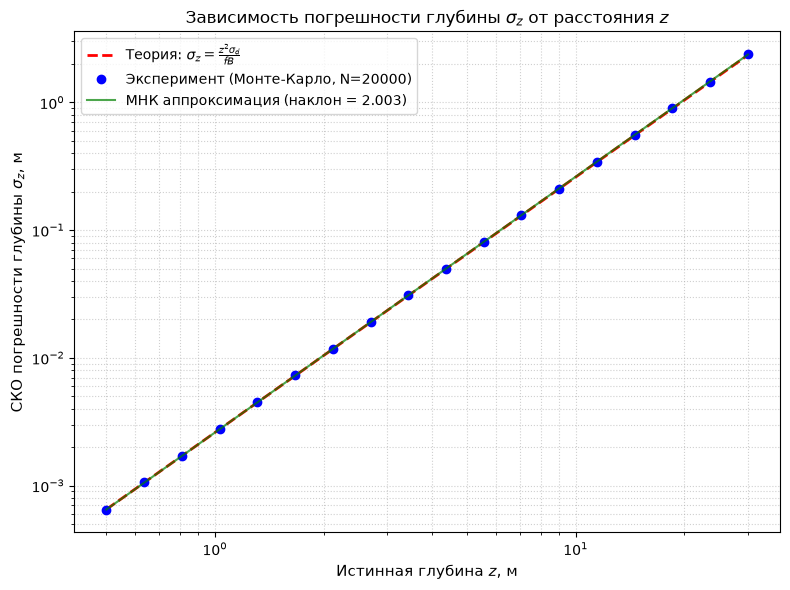

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ==================== 1. ПАРАМЕТРЫ ЭКСПЕРИМЕНТА ====================
f_val = 800.0        # Фокусное расстояние в пикселях
B_val = 0.12         # База стереопары в метрах (12 см)
sigma_d = 0.25       # СКО шума диспаратности в пикселях
N_trials = 20000     # Количество монте-карло испытаний на каждую точку

# 18 логарифмически равномерных значений глубины от 0.5 до 30 м
z_values = np.geomspace(0.5, 30.0, 18)

# Теоретическая оценка СКО по формуле линеаризации: sigma_z = (z^2 * sigma_d) / (f * B)
sigma_z_theory = (z_values**2 * sigma_d) / (f_val * B_val)

# ==================== 2. СТАТИСТИЧЕСКОЕ МОДЕЛИРОВАНИЕ ====================
rng = np.random.default_rng(0)
sigma_z_emp = []

for z in z_values:
    # Истинная диспаратность
    d_true = (f_val * B_val) / z
    
    # Добавление гауссова шума: d_noisy ~ N(d_true, sigma_d^2)
    noise = rng.normal(0.0, sigma_d, size=N_trials)
    d_noisy = d_true + noise
    
    # Восстановление глубины
    z_recovered = (f_val * B_val) / d_noisy
    
    # Оценка выборочного стандартного отклонения (СКО)
    sigma_z_emp.append(np.std(z_recovered, ddof=1))

sigma_z_emp = np.array(sigma_z_emp)

# ==================== 3. ОЦЕНКА НАКЛОНА МЕТОДОМ МНК ====================
# В log-log масштабе: ln(sigma_z) = slope * ln(z) + const
log_z = np.log(z_values)
log_sigma = np.log(sigma_z_emp)

# МНК-аппроксимация полиномом 1-й степени
slope, intercept = np.polyfit(log_z, log_sigma, 1)

print(f"Оценка наклона прямой в log-log масштабе: {slope:.4f} (ожидается ≈ 2.0)")
assert np.isclose(slope, 2.0, atol=0.08), f"Наклон {slope:.4f} существенно отличается от 2!"

# ==================== 4. СРАВНЕНИЕ ПРИ z = 4 м И ПОРОГ 10% ====================
z_ref = 4.0
d_ref = (f_val * B_val) / z_ref
th_ref = (z_ref**2 * sigma_d) / (f_val * B_val)
d_noisy_ref = d_ref + rng.normal(0.0, sigma_d, size=N_trials)
emp_ref = np.std((f_val * B_val) / d_noisy_ref, ddof=1)

print(f"\nСравнение при z = {z_ref} м:")
print(f"  Теоретическое СКО:  {th_ref:.6f} м ({th_ref*100:.2f} см)")
print(f"  Эмпирическое СКО:   {emp_ref:.6f} м ({emp_ref*100:.2f} см)")
print(f"  Относительное расхождение: {abs(emp_ref - th_ref) / th_ref * 100:.2f}%")

# Аналитический расчёт глубины, где sigma_z / z >= 0.10:
# sigma_z / z = (z * sigma_d) / (f * B) = 0.10 => z = 0.10 * f * B / sigma_d
z_10_percent = 0.10 * (f_val * B_val) / sigma_d
print(f"\nГлубина, на которой погрешность превышает 10% от самой глубины: {z_10_percent:.2f} м")

# ==================== 5. ПОСТРОЕНИЕ ГРАФИКА ====================
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

ax.loglog(z_values, sigma_z_theory, 'r--', lw=2, label=r"Теория: $\sigma_z = \frac{z^2 \sigma_d}{f B}$")
ax.loglog(z_values, sigma_z_emp, 'bo', markersize=6, label=f"Эксперимент (Монте-Карло, N={N_trials})")
ax.loglog(z_values, np.exp(intercept) * (z_values**slope), 'g-', lw=1.5, alpha=0.7, 
          label=f"МНК аппроксимация (наклон = {slope:.3f})")

ax.set_title(r"Зависимость погрешности глубины $\sigma_z$ от расстояния $z$", fontsize=12)
ax.set_xlabel(r"Истинная глубина $z$, м", fontsize=11)
ax.set_ylabel(r"СКО погрешности глубины $\sigma_z$, м", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()


## Задание 6. Влияние базы

Зафиксируйте глубину $z = 6$ м и повторите эксперимент для базы от 3 до 50 см.
Оцените наклон зависимости погрешности от базы в логарифмическом масштабе.

**Контроль.** Наклон должен быть близок к $-1$.

**Вопрос для вывода:** во сколько раз нужно увеличить базу, чтобы вдвое уменьшить
погрешность? Какие практические ограничения мешают делать базу большой?

Оценка наклона зависимости от базы в log-log масштабе: -1.0051 (ожидается ≈ -1.0)


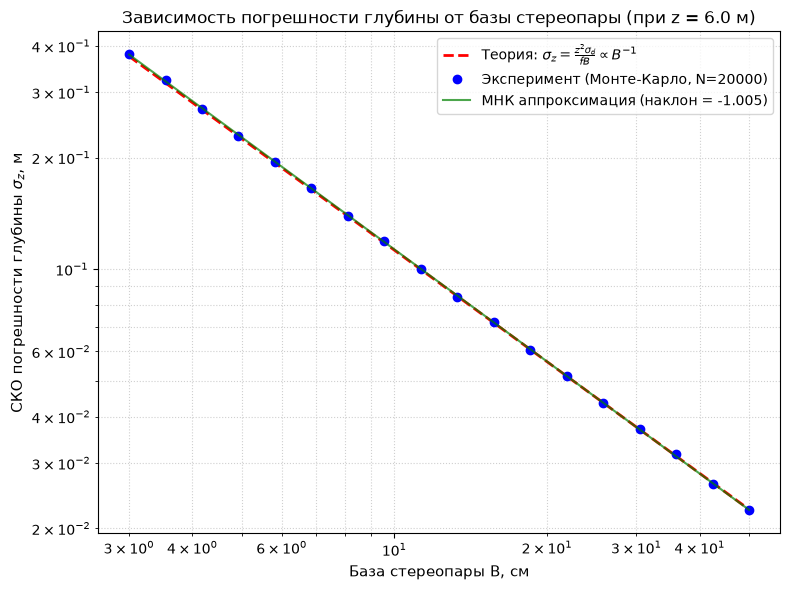

In [7]:
# ==================== 1. ПАРАМЕТРЫ ЭКСПЕРИМЕНТА ====================
f_val = 800.0        # Фокусное расстояние в пикселях
z_fixed = 6.0        # Фиксированная глубина в метрах
sigma_d = 0.25       # СКО шума диспаратности в пикселях
N_trials = 20000     # Количество испытаний Монте-Карло

# База стереопары от 3 до 50 см (18 точек, логарифмически равномерно)
B_values = np.geomspace(0.03, 0.50, 18)

# Теоретическая кривая: sigma_z = (z^2 * sigma_d) / (f * B)
sigma_z_theory_B = (z_fixed**2 * sigma_d) / (f_val * B_values)

# ==================== 2. СТАТИСТИЧЕСКОЕ МОДЕЛИРОВАНИЕ ====================
rng = np.random.default_rng(0)
sigma_z_emp_B = []

for B in B_values:
    # Истинная диспаратность
    d_true = (f_val * B) / z_fixed
    
    # Добавление гауссова шума: d_noisy ~ N(d_true, sigma_d^2)
    noise = rng.normal(0.0, sigma_d, size=N_trials)
    d_noisy = d_true + noise
    
    # Восстановление глубины
    z_rec = (f_val * B) / d_noisy
    
    # Оценка выборочного СКО
    sigma_z_emp_B.append(np.std(z_rec, ddof=1))

sigma_z_emp_B = np.array(sigma_z_emp_B)

# ==================== 3. ОЦЕНКА НАКЛОНА МЕТОДОМ МНК ====================
# В log-log масштабе: ln(sigma_z) = slope * ln(B) + const
log_B = np.log(B_values)
log_sigma_B = np.log(sigma_z_emp_B)

slope_B, intercept_B = np.polyfit(log_B, log_sigma_B, 1)

print(f"Оценка наклона зависимости от базы в log-log масштабе: {slope_B:.4f} (ожидается ≈ -1.0)")
assert np.isclose(slope_B, -1.0, atol=0.05), f"Наклон {slope_B:.4f} существенно отличается от -1!"

# ==================== 4. ПОСТРОЕНИЕ ГРАФИКА ====================
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

ax.loglog(B_values * 100, sigma_z_theory_B, 'r--', lw=2, 
          label=r"Теория: $\sigma_z = \frac{z^2 \sigma_d}{f B} \propto B^{-1}$")
ax.loglog(B_values * 100, sigma_z_emp_B, 'bo', markersize=6, 
          label=f"Эксперимент (Монте-Карло, N={N_trials})")
ax.loglog(B_values * 100, np.exp(intercept_B) * (B_values**slope_B), 'g-', lw=1.5, alpha=0.7, 
          label=f"МНК аппроксимация (наклон = {slope_B:.3f})")

ax.set_title(f"Зависимость погрешности глубины от базы стереопары (при z = {z_fixed} м)", fontsize=12)
ax.set_xlabel("База стереопары B, см", fontsize=11)
ax.set_ylabel(r"СКО погрешности глубины $\sigma_z$, м", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.show()


## Задание 7. Триангуляция в общем случае (дополнительное)

Параллельные камеры — частный случай. В общем положении глубина находится
триангуляцией: по двум проекциям $x_1, x_2$ и матрицам $P_1, P_2$ составляется
однородная система $A\tilde{X} = 0$, решаемая через SVD, — та же схема, что
в задании 4 лабораторной работы № 4 и в графовом SLAM.

Реализуйте `triangulate_dlt(P1, P2, x1, x2)`, восстановите 200 случайных точек
по двум непараллельным камерам и оцените ошибку без шума и при шуме 0,5 пикселя.

**Контроль.** Без шума ошибка на уровне $10^{-14}$ м.

In [8]:
# ==================== 1. РЕАЛИЗАЦИЯ МЕТОДА DLT ЧЕРЕЗ SVD ====================
def triangulate_dlt(P1, P2, x1, x2):
    """
    Линейная триангуляция (DLT) на основе SVD для двух камер общего положения.
    
    Параметры:
      P1, P2: проекционные матрицы камер размером 3x4 (P = K @ [R | t])
      x1, x2: пиксельные координаты проекций на кадрах размером (N, 2)
      
    Возвращает:
      X_3d: восстановленные координаты 3D-точек размером (N, 3)
    """
    x1 = np.atleast_2d(x1).astype(float)
    x2 = np.atleast_2d(x2).astype(float)
    N = len(x1)
    
    X_3d = np.zeros((N, 3), dtype=float)
    
    for i in range(N):
        u1, v1 = x1[i]
        u2, v2 = x2[i]
        
        # Для каждой камеры уравнение векторного произведения [x]_x * P * X = 0
        # даёт два линейно независимых уравнения:
        #   u * P[2, :] - P[0, :] = 0
        #   v * P[2, :] - P[1, :] = 0
        A = np.array([
            u1 * P1[2, :] - P1[0, :],
            v1 * P1[2, :] - P1[1, :],
            u2 * P2[2, :] - P2[0, :],
            v2 * P2[2, :] - P2[1, :]
        ], dtype=float)
        
        # Решение однородной системы A * X_hom = 0 через SVD
        # Правый сингулярный вектор, отвечающий минимальному сингулярному числу (последняя строка Vh)
        _, _, Vh = np.linalg.svd(A)
        X_hom = Vh[-1]
        
        # Денормализация однородных координат: деление на 4-ю компоненту w
        X_3d[i] = X_hom[:3] / X_hom[3]
        
    return X_3d


# ==================== 2. ГЕНЕРАЦИЯ КАМЕР И ТОЧЕК ====================
rng = np.random.default_rng(42)

# Внутренние параметры камер
f, cx, cy = 800.0, 640.0, 360.0
K = intrinsics(f, cx, cy)

# 1-я камера (слева, смотрит на сцену)
eye1 = np.array([-0.3, -2.5, 0.4])
target1 = np.array([0.0, 0.0, 2.5])
up1 = np.array([0.0, 0.0, 1.0])
R1, t1 = look_at(eye1, target1, up1)
P1 = K @ np.column_stack([R1, t1])

# 2-я камера (справа и под углом, непараллельная стереопара)
eye2 = np.array([0.4, -2.3, 0.7])
target2 = np.array([0.0, 0.0, 2.5])
up2 = np.array([0.1, 0.0, 1.0])
R2, t2 = look_at(eye2, target2, up2)
P2 = K @ np.column_stack([R2, t2])

# Генерируем 200 случайных 3D-точек в рабочем объёме сцены
N_pts = 200
X_true = np.column_stack([
    rng.uniform(-0.6, 0.6, N_pts),    # X
    rng.uniform(-0.4, 0.4, N_pts),    # Y
    rng.uniform(2.0, 3.5, N_pts)      # Z (глубина)
])

# Точные проекции на плоскости изображений
uv1_ideal, depth1 = project(K, R1, t1, X_true)
uv2_ideal, depth2 = project(K, R2, t2, X_true)
assert np.all(depth1 > 0) and np.all(depth2 > 0), "Все точки должны лежать перед камерами!"


# ==================== 3. ЭКСПЕРИМЕНТ 1: БЕЗ ШУМА ====================
X_rec_noiseless = triangulate_dlt(P1, P2, uv1_ideal, uv2_ideal)

# Евклидово расстояние между восстановленными и истинными 3D-точками
errors_noiseless = np.linalg.norm(X_rec_noiseless - X_true, axis=1)
max_err_noiseless = np.max(errors_noiseless)
mean_err_noiseless = np.mean(errors_noiseless)

print("=" * 60)
print(f"Эксперимент 1 (без шума):")
print(f"  Максимальная ошибка: {max_err_noiseless:.3e} м")
print(f"  Средняя ошибка:      {mean_err_noiseless:.3e} м")

assert max_err_noiseless < 1e-12, "Ошибка без шума превышает допустимый предел!"


# ==================== 4. ЭКСПЕРИМЕНТ 2: С ШУМОМ 0.5 ПИКСЕЛЯ ====================
sigma_noise = 0.5
noise1 = rng.normal(0.0, sigma_noise, size=uv1_ideal.shape)
noise2 = rng.normal(0.0, sigma_noise, size=uv2_ideal.shape)

uv1_noisy = uv1_ideal + noise1
uv2_noisy = uv2_ideal + noise2

X_rec_noisy = triangulate_dlt(P1, P2, uv1_noisy, uv2_noisy)

errors_noisy = np.linalg.norm(X_rec_noisy - X_true, axis=1)
print("\n" + "=" * 60)
print(f"Эксперимент 2 (шум sigma = {sigma_noise} пикселя):")
print(f"  Максимальная 3D-ошибка: {np.max(errors_noisy):.4f} м ({np.max(errors_noisy)*100:.2f} см)")
print(f"  Средняя 3D-ошибка:      {np.mean(errors_noisy):.4f} м ({np.mean(errors_noisy)*100:.2f} см)")
print(f"  СКО ошибки:             {np.std(errors_noisy):.4f} м ({np.std(errors_noisy)*100:.2f} см)")


# ==================== 5. СВЕРКА С OPENCV ====================
try:
    import cv2
    
    # cv2.triangulatePoints ожидает проекции в формате (2, N) и возвращает (4, N)
    pts4d_cv = cv2.triangulatePoints(P1, P2, uv1_ideal.T, uv2_ideal.T)
    X_cv_noiseless = (pts4d_cv[:3] / pts4d_cv[3]).T
    
    cv_diff = np.linalg.norm(X_rec_noiseless - X_cv_noiseless)
    print("\n" + "=" * 60)
    print("Сверка с OpenCV (cv2.triangulatePoints):")
    print(f"  ||X_dlt - X_cv2|| = {cv_diff:.3e} м")
    assert cv_diff < 1e-12, "Сверка с cv2.triangulatePoints не сошлась!"
    print("  Контрольная сверка с OpenCV пройдена успешно!")
except ImportError:
    print("\n" + "=" * 60)
    print("Библиотека opencv-python не установлена, сверка пропущена.")


Эксперимент 1 (без шума):
  Максимальная ошибка: 6.417e-15 м
  Средняя ошибка:      2.071e-15 м

Эксперимент 2 (шум sigma = 0.5 пикселя):
  Максимальная 3D-ошибка: 0.0462 м (4.62 см)
  Средняя 3D-ошибка:      0.0122 м (1.22 см)
  СКО ошибки:             0.0089 м (0.89 см)

Библиотека opencv-python не установлена, сверка пропущена.


## Выводы

_Ответьте на все вопросы, отмеченные как «вопрос для вывода», приводя конкретные числа._

## Контрольные вопросы

1. Что содержит матрица $K$ и что — пара $[R \mid t]$? Какая из них меняется при
   перемещении камеры?
2. Почему проективное преобразование записывается матрицей, у которой нижняя строка
   не равна $(0,0,0,1)$? Откуда берётся деление на третью координату?
3. Как связаны фокусное расстояние в миллиметрах и в пикселях?
4. Какой тип дисторсии даёт отрицательный $k_1$, какой — положительный?
5. Почему обратное к дисторсии преобразование ищут итерациями?
6. Выведите формулу $z = fB/d$ из подобия треугольников.
7. Выведите закон роста погрешности $\delta z = z^2 \delta d /(fB)$.
8. Почему стереозрение перестаёт работать на больших расстояниях? Оцените предельную
   дальность для базы 6,3 см и точности диспаратности 0,25 пикселя.
9. Что такое эпиполярная линия и почему поиск соответствий ведут вдоль неё?
10. Как связаны задача триангуляции и задача оценки гомографии из темы 5?